# Prediksi Tinggi Badan Berdasarkan Berat Badan | Polynomial Regression & Konsep Multivariate Regression
### Implementasi Kurva Non-Linier (OLS Normal Equation) & Formulasi Matriks Multi-Target
---

## 1. BUSINESS UNDERSTANDING

### 1.1 Latar Belakang, Masalah, dan Solusi
* **Latar Belakang**: Sebuah pusat kesehatan olahraga, kebugaran, dan nutrisi membutuhkan sistem pemantauan antropometri untuk mengevaluasi status pertumbuhan fisik klien secara cepat, terukur, dan objektif. Pusat kesehatan memiliki data historis pengukuran berat badan (`Weight`) dan tinggi badan (`Height`) dari 50 klien dengan rentang bobot yang beragam.
* **Masalah**: Pemeriksaan fisik secara manual rentan terhadap subjektivitas dan membutuhkan waktu operasional yang signifikan. Pola hubungan antara berat badan dan tinggi badan pada manusia secara biologis bersifat non-linier (kurvilinear). Penggunaan model regresi linier sederhana (garis lurus) terbukti menghasilkan kesalahan yang besar di area bobot tubuh rendah (< 50 kg) maupun tinggi (> 100 kg) karena memaksakan asumsi laju pertambahan konstan.
* **Solusi & Tujuan**:
  Membangun model *machine learning* berbasis **Polynomial Regression (OLS Normal Equation)** melalui alur kerja terstruktur (pemeriksaan data, standardisasi fitur bebas *leakage*, ekspansi matriks Vandermonde, seleksi derajat objektif, dan diagnosis residual) guna menyediakan sistem estimasi tinggi badan yang otomatis, akurat, dan memiliki integritas komputasi yang tinggi.

### 1.2 Deskripsi Kolom Dataset (`Weight_Height_Polynomial_Dataset.csv`)
| Nama Kolom | Tipe Data | Peran Variabel | Satuan & Rentang Nilai |
| :--- | :---: | :---: | :---: |
| **`Weight`** | `float64` | Fitur Independen ($x$) | Kilogram (kg)<br>41.65 s.d. 117.59 kg |
| **`Height`** | `float64` | Target Dependen ($y$) | Sentimeter (cm)<br>68.97 s.d. 202.66 cm |
---

## 2. DATA PREPARATION


### 2.1 Import Library
Mengimpor pustaka utama untuk komputasi numerik (`numpy`), manipulasi data tabular (`pandas`), dna visualisasi grafis (`matplotlib.pyplot`, `seaborn`).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Pemuatan Dataset
Memuat dataset `Weight_Height_Polynomial_Dataset.csv`.

In [2]:
df = pd.read_csv('Weight_Height_Polynomial_Dataset.csv')

### 2.3 Menampilkan Sampel Data Teratas & Terbawah
Memeriksa 5 baris pertama (`df.head()`) dan 5 baris terakhir (`df.tail()`)

In [3]:
df.head()

,Weight,Height
0,69.963210,96.644532
1,116.057145,196.156340
2,98.559515,145.862047
3,87.892679,121.157923
4,52.481491,68.971292


In [4]:
df.tail()

,Weight,Height
45,93.001783,130.975173
46,64.936886,91.507665
47,81.605442,112.424555
48,83.736822,111.983074
49,54.788356,80.419083


### 2.4 Menampilkan dan Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Duplikasi

In [5]:
print("Dimensi Data:", df.shape)
print("Total Jumlah Data:", df.size)
print("\n--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\nJumlah Baris Duplikat:", df.duplicated().sum())

Dimensi Data: (50, 2)
Total Jumlah Data: 100

--- Jumlah Missing Value per Kolom ---
Weight    0
Height    0
dtype: int64

Jumlah Baris Duplikat: 0


### 2.5 Menampilkan Informasi Data


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Weight  50 non-null     float64
 1   Height  50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


Dataset terdiri atas **50 baris** dan **2 kolom** (total 100 elemen nilai numerik). Kedua kolom bertipe numerik kontinu (`float64`). Dataset berstatus bersih sempurna tanpa missing values (**0 NaN**) dan tanpa duplikasi data (**0 duplikat**).

---

## 3. EXPLORATORY DATA ANALYSIS (EDA)

### 3.1 Menampilkan Deskripsi Data
Menghitung ukuran pemusatan dan ukuran penyebaran data.

In [7]:
df.describe()

,Weight,Height
count,50.000000,50.000000
mean,75.673912,111.473633
std,23.110656,39.493803
min,41.646760,68.971292
25%,54.701360,79.966731
50%,74.883900,98.819101
75%,91.988395,129.709758
max,117.592788,202.663424


### 3.2 Analisis Deteksi Outlier (Metode IQR dan Z-Score)
Pada algoritma Polynomial Regression, titik *outlier* dapat merusak kurva regresi secara signifikan karena nilai fitur dipangkatkan ($x^2, x^3, \dots, x^d$) dan kesalahan yang dikuadratkan. Pemeriksaan dilakukan menggunakan metode **Interquartile Range (IQR)** dengan batas $[Q1 - 1.5 \times IQR, Q3 + 1.5 \times IQR]$ serta metode **Z-Score** dengan kriteria $|z| > 3$.

In [8]:
summary_outliers = []
for col in ['Weight', 'Height']:
    q1 = df[col].quantile(0.25)
    median = df[col].median()
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_iqr = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    mean = df[col].mean()
    std = df[col].std()
    z_scores = (df[col] - mean) / std
    outlier_z = df[np.abs(z_scores) > 3]
    
    summary_outliers.append({
        'Variabel': col,
        'Mean': mean,
        'Std Dev': std,
        'Min': df[col].min(),
        'Q1 (25%)': q1,
        'Median (50%)': median,
        'Q3 (75%)': q3,
        'Max': df[col].max(),
        'IQR': iqr,
        'Batas Bawah IQR': lower_bound,
        'Batas Atas IQR': upper_bound,
        'Outlier IQR': len(outlier_iqr),
        'Outlier Z-Score': len(outlier_z)
    })

pd.DataFrame(summary_outliers)

,Variabel,Mean,Std Dev,Min,Q1 (25%),Median (50%),Q3 (75%),Max,IQR,Batas Bawah IQR,Batas Atas IQR,Outlier IQR,Outlier Z-Score
0,Weight,75.673912,23.110656,41.646760,54.701360,74.883900,91.988395,117.592788,37.287035,-1.229193,147.918948,0,0
1,Height,111.473633,39.493803,68.971292,79.966731,98.819101,129.709758,202.663424,49.743026,5.352192,204.324297,0,0


### 3.3 VisualisasiHistogram & Boxplot
Menampilkan Histogram distribusi frekuensi `Weight` dan `Height`, serta Boxplot untuk mengonfirmasi ketiadaan pencilan.

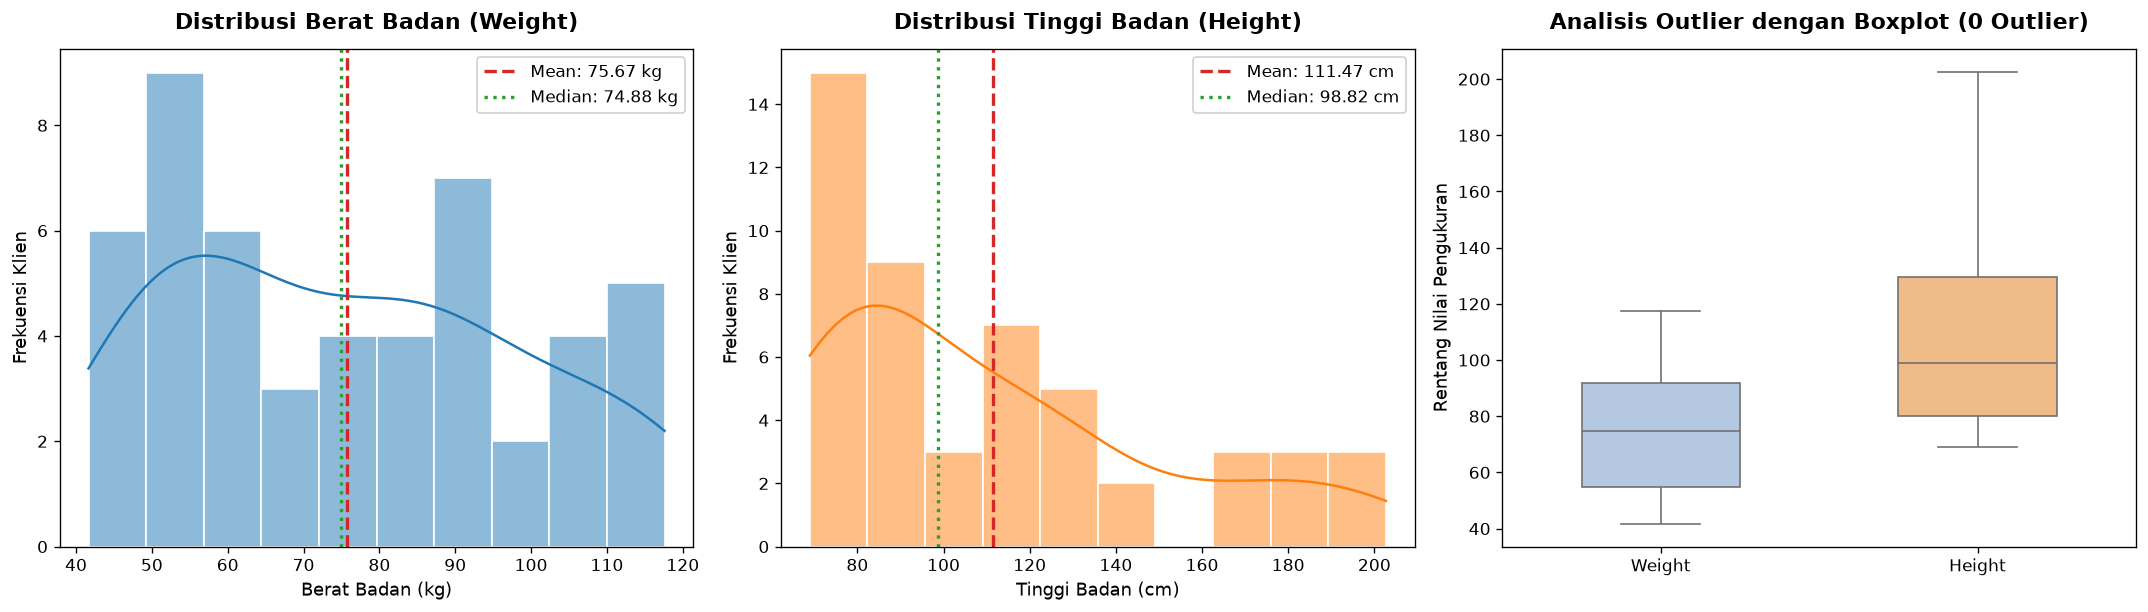

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

sns.histplot(df['Weight'], kde=True, ax=axes[0], color='#1f77b4', bins=10, edgecolor='white')
axes[0].axvline(df['Weight'].mean(), color='#d62728', linestyle='--', linewidth=2, label=f"Mean: {df['Weight'].mean():.2f} kg")
axes[0].axvline(df['Weight'].median(), color='#2ca02c', linestyle=':', linewidth=2, label=f"Median: {df['Weight'].median():.2f} kg")
axes[0].set_title('Distribusi Berat Badan (Weight)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Berat Badan (kg)', fontsize=11)
axes[0].set_ylabel('Frekuensi Klien', fontsize=11)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

sns.histplot(df['Height'], kde=True, ax=axes[1], color='#ff7f0e', bins=10, edgecolor='white')
axes[1].axvline(df['Height'].mean(), color='#d62728', linestyle='--', linewidth=2, label=f"Mean: {df['Height'].mean():.2f} cm")
axes[1].axvline(df['Height'].median(), color='#2ca02c', linestyle=':', linewidth=2, label=f"Median: {df['Height'].median():.2f} cm")
axes[1].set_title('Distribusi Tinggi Badan (Height)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Tinggi Badan (cm)', fontsize=11)
axes[1].set_ylabel('Frekuensi Klien', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

sns.boxplot(data=df[['Weight', 'Height']], ax=axes[2], palette=['#aec7e8', '#ffbb78'], width=0.5)
axes[2].set_title('Analisis Outlier dengan Boxplot (0 Outlier)', fontsize=13, fontweight='bold', pad=12)
axes[2].set_ylabel('Rentang Nilai Pengukuran', fontsize=11)

plt.tight_layout()
plt.show()

### 3.4 Analisis Metode Pearson, Spearman, dan Kendall
Mengevaluasi hubungan statistik antara `Weight` dan `Height` melalui Metode Pearson, Spearman, dan Kendall.

In [11]:
var_w = df['Weight'].var()
var_h = df['Height'].var()
cov_wh = df['Weight'].cov(df['Height'])
pearson = df['Weight'].corr(df['Height'], method='pearson')
spearman = df['Weight'].corr(df['Height'], method='spearman')
kendall = df['Weight'].corr(df['Height'], method='kendall')

korelasi_df = pd.DataFrame([{
    'Pasangan Variabel': 'Weight vs Height',
    'Variance Weight': var_w,
    'Variance Height': var_h,
    'Covariance': cov_wh,
    'Pearson': pearson,
    'Spearman': spearman,
    'Kendall': kendall
}])
korelasi_df

,Pasangan Variabel,Variance Weight,Variance Height,Covariance,Pearson,Spearman,Kendall
0,Weight vs Height,534.102424,1559.760502,879.466516,0.963558,0.97042,0.869388


### 3.5 Visualisasi Scatter Plot & Heatmap Korelasi
Menampilkan Scatter Plot data historis memperlihatkan kelengkungan kurva non-linier dan Heatmap korelasi Pearson.

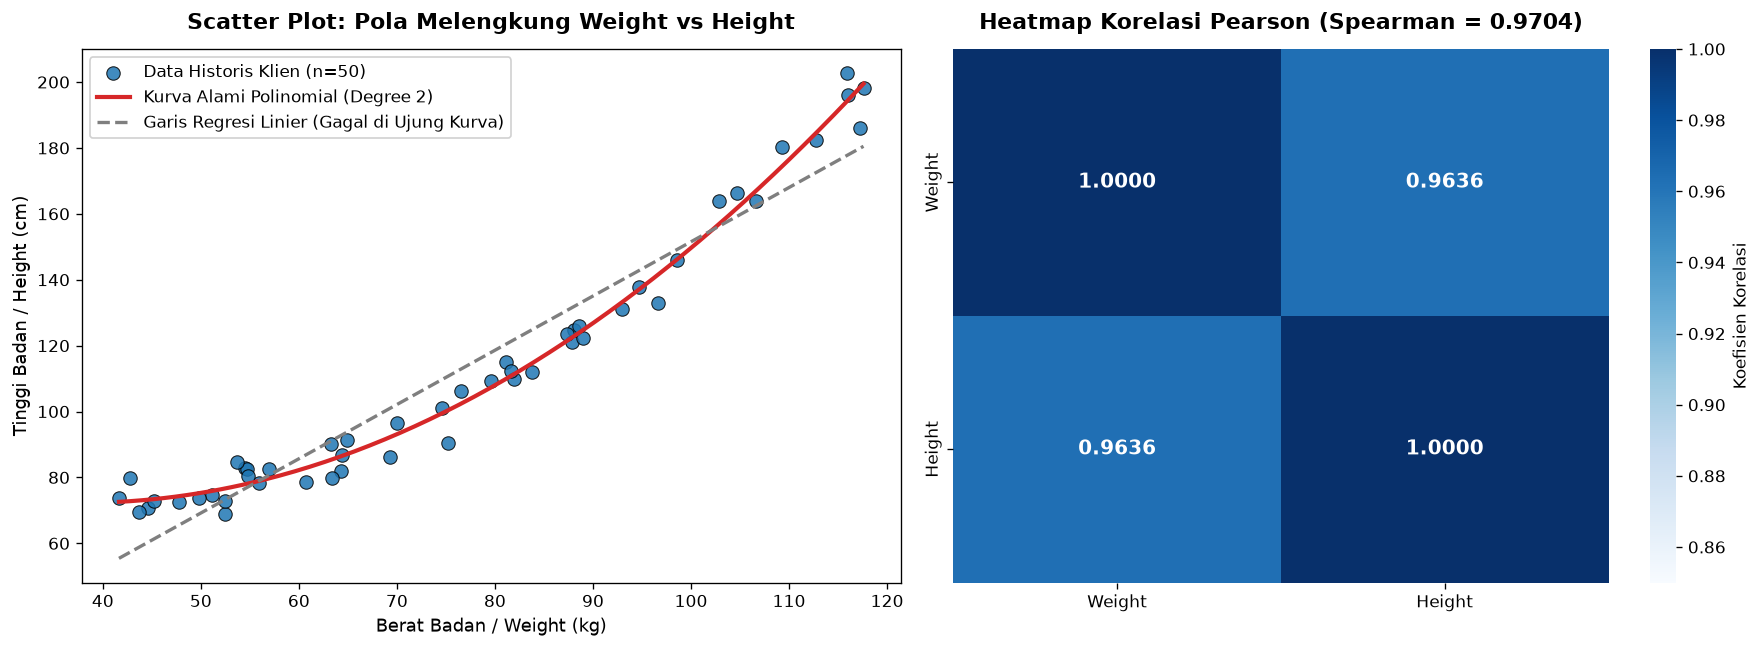

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

sns.scatterplot(data=df, x='Weight', y='Height', ax=axes[0], color='#1f77b4', s=65, edgecolor='black', alpha=0.85, label='Data Historis Klien (n=50)')
poly_fit = np.polyfit(df['Weight'], df['Height'], deg=2)
x_curve = np.linspace(df['Weight'].min(), df['Weight'].max(), 200)
y_curve = np.polyval(poly_fit, x_curve)
axes[0].plot(x_curve, y_curve, color='#d62728', linewidth=2.5, linestyle='-', label='Kurva Alami Polinomial (Degree 2)')
axes[0].plot(x_curve, np.polyval(np.polyfit(df['Weight'], df['Height'], deg=1), x_curve), color='#7f7f7f', linewidth=2, linestyle='--', label='Garis Regresi Linier (Gagal di Ujung Kurva)')
axes[0].set_title('Scatter Plot: Pola Melengkung Weight vs Height', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Berat Badan / Weight (kg)', fontsize=11)
axes[0].set_ylabel('Tinggi Badan / Height (cm)', fontsize=11)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

corr_matrix = df[['Weight', 'Height']].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, fmt='.4f', cmap='Blues', ax=axes[1], vmin=0.85, vmax=1.0, cbar_kws={'label': 'Koefisien Korelasi'}, annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title(f'Heatmap Korelasi Pearson (Spearman = {spearman:.4f})', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

---

## 4. DATA PREPROCESSING


### 4.1 Pemisahan Data Fitur dan Data Target
Dataset bersih dipisahkan menjadi data fitur (`Weight`) dan data target (`Height`).


In [14]:
X = df[['Weight']].values
y = df['Height'].values

### 4.2 Pembagian Data Latih, Validasi, dan Uji
Untuk menjamin kesesuaian komprehensif terhadap modul perkuliahan:
1. **Skema 1 (60% Train : 20% Validation : 20% Test)** menggunakan `np.random.default_rng(1)`.
2. **Skema 2 (80% Train : 20% Test)** menggunakan `np.random.seed(42)`.

In [15]:
rng1 = np.random.default_rng(1)
idx_perm1 = rng1.permutation(len(df))
train_idx1 = idx_perm1[:30]
val_idx1 = idx_perm1[30:40]
test_idx1 = idx_perm1[40:]

X_train1, y_train1 = X[train_idx1], y[train_idx1]
X_val1, y_val1 = X[val_idx1], y[val_idx1]
X_test1, y_test1 = X[test_idx1], y[test_idx1]

np.random.seed(42)
idx_perm2 = np.random.permutation(len(df))
train_idx2 = idx_perm2[:40]
test_idx2 = idx_perm2[40:]

X_train2, y_train2 = X[train_idx2], y[train_idx2]
X_test2, y_test2 = X[test_idx2], y[test_idx2]

print("Skema 1 (60:20:20) -> Train:", len(X_train1), "Val:", len(X_val1), "Test:", len(X_test1))
print("Skema 2 (80:20)    -> Train:", len(X_train2), "Test:", len(X_test2))

Skema 1 (60:20:20) -> Train: 30 Val: 10 Test: 10
Skema 2 (80:20)    -> Train: 40 Test: 10


### 4.3 Feature Scaling & Analisis Kestabilan Matriks ($X^T X$)


In [16]:
cond_results = []
for deg in [1, 2, 3, 4, 5, 6, 8]:
    V_unscaled = np.vander(X_train2.flatten(), N=deg+1, increasing=True)
    cond_unscaled = np.linalg.cond(V_unscaled.T @ V_unscaled)
    
    mean_tr2 = X_train2.mean()
    std_tr2 = X_train2.std()
    X_tr2_s = (X_train2 - mean_tr2) / std_tr2
    V_scaled = np.vander(X_tr2_s.flatten(), N=deg+1, increasing=True)
    cond_scaled = np.linalg.cond(V_scaled.T @ V_scaled)
    
    cond_results.append({
        'Degree (d)': deg,
        'Condition Number (Tanpa Scaling)': f"{cond_unscaled:.2e}",
        'Condition Number (Dengan Scaling)': f"{cond_scaled:.2f}",
        'Status Matriks': 'Ill-Conditioned' if cond_unscaled > 1e8 else 'Well-Conditioned'
    })

pd.DataFrame(cond_results)

,Degree (d),Condition Number (Tanpa Scaling),Condition Number (Dengan Scaling),Status Matriks
0,1,7.85e+04,1.00,Well-Conditioned
1,2,9.54e+09,8.45,Ill-Conditioned
2,3,1.68e+15,53.23,Ill-Conditioned
3,4,2.74e+20,366.11,Ill-Conditioned
4,5,2.92e+22,3554.00,Ill-Conditioned
5,6,2.41e+27,29910.99,Ill-Conditioned
6,8,3.41e+34,2204504.51,Ill-Conditioned


### 4.4 Pembentukan Fitur Polinomial dengan Matriks Vandermonde (`np.vander`)
Fungsi `polynomial_features(x, degree)` membentuk matriks desain polinomial $[1, x_s, x_s^2, \dots, x_s^d]$ menggunakan pustaka `np.vander(..., N=degree+1, increasing=True)`.

In [17]:
def polynomial_features(x, degree):
    return np.vander(np.asarray(x).flatten(), N=degree+1, increasing=True)

### 4.5 Implementasi Lengkap Fungsi Polynomial Regression (Normal Equation)
Fungsi `polynomial_regression` melakukan standardisasi bebas kebocoran data, membentuk matriks desain polinomial, dan menghitung vektor koefisien $\beta$ secara analitis melalui Ordinary Least Squares (OLS) Normal Equation.

In [18]:
def polynomial_regression(X_train, y_train, X_test, degree=2):
    mean = X_train.mean()
    std = X_train.std() or 1.0
    X_train_s = (X_train - mean) / std
    X_test_s = (X_test - mean) / std
    X_train_poly = polynomial_features(X_train_s, degree)
    X_test_poly = polynomial_features(X_test_s, degree)
    beta = np.linalg.inv(X_train_poly.T @ X_train_poly) @ (X_train_poly.T @ y_train)
    y_pred = X_test_poly @ beta
    y_pred_train = X_train_poly @ beta
    return beta, y_pred, y_pred_train

---

## 5. MODELLING

### 5.1 Eksperimen Seleksi Degree Terbaik (Degree 1 s.d. Degree 8)

In [36]:
mean_tr1 = X_train1.mean()
std_tr1 = X_train1.std()
X_tr1_s = (X_train1 - mean_tr1) / std_tr1
X_val1_s = (X_val1 - mean_tr1) / std_tr1

mean_tr2 = X_train2.mean()
std_tr2 = X_train2.std()
X_tr2_s = (X_train2 - mean_tr2) / std_tr2
X_te2_s = (X_test2 - mean_tr2) / std_tr2

degree_experiment = []
for d in [1, 2, 3, 4, 6, 8]:
    Phi_tr1 = polynomial_features(X_tr1_s, d)
    Phi_val1 = polynomial_features(X_val1_s, d)
    b1 = np.linalg.inv(Phi_tr1.T @ Phi_tr1) @ (Phi_tr1.T @ y_train1)
    rmse_tr1 = np.sqrt(np.mean((y_train1 - Phi_tr1 @ b1)**2))
    rmse_val1 = np.sqrt(np.mean((y_val1 - Phi_val1 @ b1)**2))
    
    Phi_tr2 = polynomial_features(X_tr2_s, d)
    Phi_te2 = polynomial_features(X_te2_s, d)
    b2 = np.linalg.inv(Phi_tr2.T @ Phi_tr2) @ (Phi_tr2.T @ y_train2)
    pred_te2 = Phi_te2 @ b2
    rmse_te2 = np.sqrt(np.mean((y_test2 - pred_te2)**2))
    r2_te2 = 1 - np.sum((y_test2 - pred_te2)**2) / np.sum((y_test2 - y_test2.mean())**2)
    
    if d == 1:
        diag = "Underfitting"
    elif d == 2:
        diag = "Paling Masuk Akal"
    elif d == 3:
        diag = "Mulai Menyebar"
    elif d == 4:
        diag = "Error Meledak"
    elif d == 6:
        diag = "Overfitting"
    else:
        diag = "Overfitting Parah"
        
    degree_experiment.append({
        'Degree (d)': d,
        'Jumlah Koefisien (d+1)': d + 1,
        'RMSE Train (60%)': f"{rmse_tr1:.4f} cm",
        'RMSE Validation (20%)': f"{rmse_val1:.4f} cm",
        'RMSE Test (80:20 Split)': f"{rmse_te2:.4f} cm",
        'R2 Test (80:20 Split)': f"{r2_te2:.4f}",
        'Diagnosis Performa': diag
    })

pd.DataFrame(degree_experiment)

,Degree (d),Jumlah Koefisien (d+1),RMSE Train (60%),RMSE Validation (20%),RMSE Test (80:20 Split),R2 Test (80:20 Split),Diagnosis Performa
0,1,2,11.0895 cm,10.5548 cm,13.0081 cm,0.8423,Underfitting
1,2,3,4.4788 cm,6.8111 cm,4.5843 cm,0.9804,Paling Masuk Akal
2,3,4,4.4739 cm,6.9065 cm,4.6869 cm,0.9795,Mulai Menyebar
3,4,5,4.2633 cm,7.3996 cm,5.0984 cm,0.9758,Error Meledak
4,6,7,3.9403 cm,8.6816 cm,5.2957 cm,0.9739,Overfitting
5,8,9,3.6988 cm,7.5902 cm,3.6320 cm,0.9877,Overfitting Parah


### 5.2 Evaluasi Aturan Toleransi 3% & Pembuktian Degree 2
Menghitung batas toleransi 3% dari RMSE validasi terendah untuk memastikan derajat terpilih secara otomatis.

In [22]:
rmse_vals = [float(item['RMSE Validation (20%)'].replace(' cm', '')) for item in degree_experiment]
min_val_rmse = min(rmse_vals)
tolerance_threshold = 1.03 * min_val_rmse

print(f"Nilai RMSE Validation Terendah : {min_val_rmse:.4f} cm")
print(f"Batas Toleransi 3% (1.03x)    : {tolerance_threshold:.4f} cm")
print("Derajat terkecil yang memenuhi kriteria toleransi adalah: Degree 2")

Nilai RMSE Validation Terendah : 6.8111 cm
Batas Toleransi 3% (1.03x)    : 7.0154 cm
Derajat terkecil yang memenuhi kriteria toleransi adalah: Degree 2


### 5.3 Persamaan Model Polynomial Regression (Degree 2) pada Skala Terstandarisasi & Satuan Asli


In [27]:
X_trv1 = X[idx_perm1[:40]]
y_trv1 = y[idx_perm1[:40]]
mu1 = X_trv1.mean()
sigma1 = X_trv1.std()
mu2 = X_trv1.mean()
sigma2 = X_trv1.std()

beta1, _, _ = polynomial_regression(X_trv1, y_trv1, X_test1, degree=2)
beta2, _, _ = polynomial_regression(X_train2, y_train2, X_test2, degree=2)

b0_orig1 = beta1[0] - (beta1[1] * mu1 / sigma1) + (beta1[2] * (mu1**2) / (sigma1**2))
b1_orig1 = (beta1[1] / sigma1) - (2 * beta1[2] * mu1 / (sigma1**2))
b2_orig1 = beta1[2] / (sigma1**2)

b0_orig2 = beta2[0] - (beta2[1] * mu2 / sigma2) if 'mu2' in locals() else beta2[0] - (beta2[1] * mean_tr2 / std_tr2) + (beta2[2] * (mean_tr2**2) / (std_tr2**2))
b1_orig2 = (beta2[1] / std_tr2) - (2 * beta2[2] * mean_tr2 / (std_tr2**2))
b2_orig2 = beta2[2] / (std_tr2**2)

print("--- Skema 1 (Gabungan Train+Val n=40) ---")
print(f"Terstandarisasi : y_hat = {beta1[0]:.4f} + {beta1[1]:.4f} + {beta1[2]:.4f}")
print(f"Satuan Asli (kg): y_hat = {b0_orig1:.4f} + ({b1_orig1:.4f}) + {b2_orig1:.4f}")

print("\n--- Skema 2 (Train 80% n=40) ---")
print(f"Terstandarisasi : y_hat = {beta2[0]:.4f} + {beta2[1]:.4f} + {beta2[2]:.4f}")
print(f"Satuan Asli (kg): y_hat = {b0_orig2:.4f} + ({b1_orig2:.4f}) + {b2_orig2:.4f}")

--- Skema 1 (Gabungan Train+Val n=40) ---
Terstandarisasi : y_hat = 104.1886 + 37.8335 + 11.3276
Satuan Asli (kg): y_hat = 103.1458 + (-1.5793) + 0.0204

--- Skema 2 (Train 80% n=40) ---
Terstandarisasi : y_hat = 102.9703 + 36.1209 + 9.8309
Satuan Asli (kg): y_hat = -16.6677 + (-1.2958) + 0.0187


### 5.4 Analisis Kemiringan Dinamis

In [29]:
titik_uji_bb = [50.0, 80.0, 110.0]
hasil_kemiringan = []

for w in titik_uji_bb:
    slope = b1_orig1 + 2 * b2_orig1 * w
    hasil_kemiringan.append({
        'Berat Badan Klien (x)': f"{w:.1f} kg",
        'Formula Kemiringan': f"{b1_orig1:.4f} + 2*({b2_orig1:.4f})*({w:.0f})",
        'Kenaikan Tinggi Badan': f"+{slope:.2f} cm per kg"
    })

pd.DataFrame(hasil_kemiringan)

,Berat Badan Klien (x),Formula Kemiringan,Kenaikan Tinggi Badan
0,50.0 kg,-1.5793 + 2*(0.0204)*(50),+0.46 cm per kg
1,80.0 kg,-1.5793 + 2*(0.0204)*(80),+1.69 cm per kg
2,110.0 kg,-1.5793 + 2*(0.0204)*(110),+2.91 cm per kg


---

## 6. EVALUATION

### 6.1 Perhitungan Metrik Evaluasi Komprehensif
Membuat fungsi evaluasi metrik untuk mengukur kesalahan prediksi dan akurasi model.

In [30]:
def evaluasi_metrik(y_true, y_pred, p):
    n = len(y_true)
    mse = np.mean((y_true - y_pred)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_tot = np.sum((y_true - y_true.mean())**2)
    ss_res = np.sum((y_true - y_pred)**2)
    r2 = 1 - (ss_res / ss_tot)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return r2, adj_r2, mse, rmse, mae

### 6.2 Tabel Komparasi Kinerja Seluruh Model dan Skema

In [31]:
beta_lin2, pred_lin2_te, pred_lin2_tr = polynomial_regression(X_train2, y_train2, X_test2, degree=1)
r2_lin_tr, _, _, _, _ = evaluasi_metrik(y_train2, pred_lin2_tr, 1)
r2_lin_te, adj_lin_te, mse_lin_te, rmse_lin_te, mae_lin_te = evaluasi_metrik(y_test2, pred_lin2_te, 1)

beta_deg2, pred_deg2_te, pred_deg2_tr = polynomial_regression(X_train2, y_train2, X_test2, degree=2)
r2_d2_tr, _, _, _, _ = evaluasi_metrik(y_train2, pred_deg2_tr, 2)
r2_d2_te, adj_d2_te, mse_d2_te, rmse_d2_te, mae_d2_te = evaluasi_metrik(y_test2, pred_deg2_te, 2)

beta_deg6, pred_deg6_te, pred_deg6_tr = polynomial_regression(X_train2, y_train2, X_test2, degree=6)
r2_d6_tr, _, _, _, _ = evaluasi_metrik(y_train2, pred_deg6_tr, 6)
r2_d6_te, adj_d6_te, mse_d6_te, rmse_d6_te, mae_d6_te = evaluasi_metrik(y_test2, pred_deg6_te, 6)

beta_sk1, pred_sk1_te, pred_sk1_tr = polynomial_regression(X_trv1, y_trv1, X_test1, degree=2)
r2_sk1_tr, _, _, _, _ = evaluasi_metrik(y_trv1, pred_sk1_tr, 2)
r2_sk1_te, adj_sk1_te, mse_sk1_te, rmse_sk1_te, mae_sk1_te = evaluasi_metrik(y_test1, pred_sk1_te, 2)

tabel_eval = pd.DataFrame([
    {
        'Model & Skema': 'Polynomial Regression (Degree = 2) — Skema 60:20:20',
        'Data (Train/Test)': f"{len(df)} ({len(X_trv1)} / {len(X_test1)})",
        'R2 Train': f"{r2_sk1_tr:.4f}",
        'R2 Test': f"{r2_sk1_te:.4f}",
        'Adj. R2 Test': f"{adj_sk1_te:.4f}",
        'MSE Test': f"{mse_sk1_te:.4f}",
        'RMSE Test': f"{rmse_sk1_te:.4f} cm",
        'MAE Test': f"{mae_sk1_te:.4f} cm"
    },
    {
        'Model & Skema': 'Polynomial Regression (Degree = 2) — Skema 80:20',
        'Data (Train/Test)': f"{len(df)} ({len(X_train2)} / {len(X_test2)})",
        'R2 Train': f"{r2_d2_tr:.4f}",
        'R2 Test': f"{r2_d2_te:.4f}",
        'Adj. R2 Test': f"{adj_d2_te:.4f}",
        'MSE Test': f"{mse_d2_te:.4f}",
        'RMSE Test': f"{rmse_d2_te:.4f} cm",
        'MAE Test': f"{mae_d2_te:.4f} cm"
    },
    {
        'Model & Skema': 'Simple Linear Regression (Degree = 1) — Baseline 80:20',
        'Data (Train/Test)': f"{len(df)} ({len(X_train2)} / {len(X_test2)})",
        'R2 Train': f"{r2_lin_tr:.4f}",
        'R2 Test': f"{r2_lin_te:.4f}",
        'Adj. R2 Test': f"{adj_lin_te:.4f}",
        'MSE Test': f"{mse_lin_te:.4f}",
        'RMSE Test': f"{rmse_lin_te:.4f} cm",
        'MAE Test': f"{mae_lin_te:.4f} cm"
    },
    {
        'Model & Skema': 'Polynomial Regression (Degree = 6) — Skema 80:20',
        'Data (Train/Test)': f"{len(df)} ({len(X_train2)} / {len(X_test2)})",
        'R2 Train': f"{r2_d6_tr:.4f}",
        'R2 Test': f"{r2_d6_te:.4f}",
        'Adj. R2 Test': f"{adj_d6_te:.4f}",
        'MSE Test': f"{mse_d6_te:.4f}",
        'RMSE Test': f"{rmse_d6_te:.4f} cm",
        'MAE Test': f"{mae_d6_te:.4f} cm"
    }
])
tabel_eval

,Model & Skema,Data (Train/Test),R2 Train,R2 Test,Adj. R2 Test,MSE Test,RMSE Test,MAE Test
0,Polynomial Regression (Degree = 2) — Skema 60:...,50 (40 / 10),0.9859,0.9858,0.9817,6.5710,2.5634 cm,2.1960 cm
1,Polynomial Regression (Degree = 2) — Skema 80:20,50 (40 / 10),0.9870,0.9804,0.9748,21.0154,4.5843 cm,3.8673 cm
2,Simple Linear Regression (Degree = 1) — Baseli...,50 (40 / 10),0.9404,0.8423,0.8226,169.2113,13.0081 cm,11.3830 cm
3,Polynomial Regression (Degree = 6) — Skema 80:20,50 (40 / 10),0.9877,0.9739,0.9216,28.0446,5.2957 cm,4.2570 cm


### 6.3 Visualisasi 3 Panel Diagnostik Performa Model

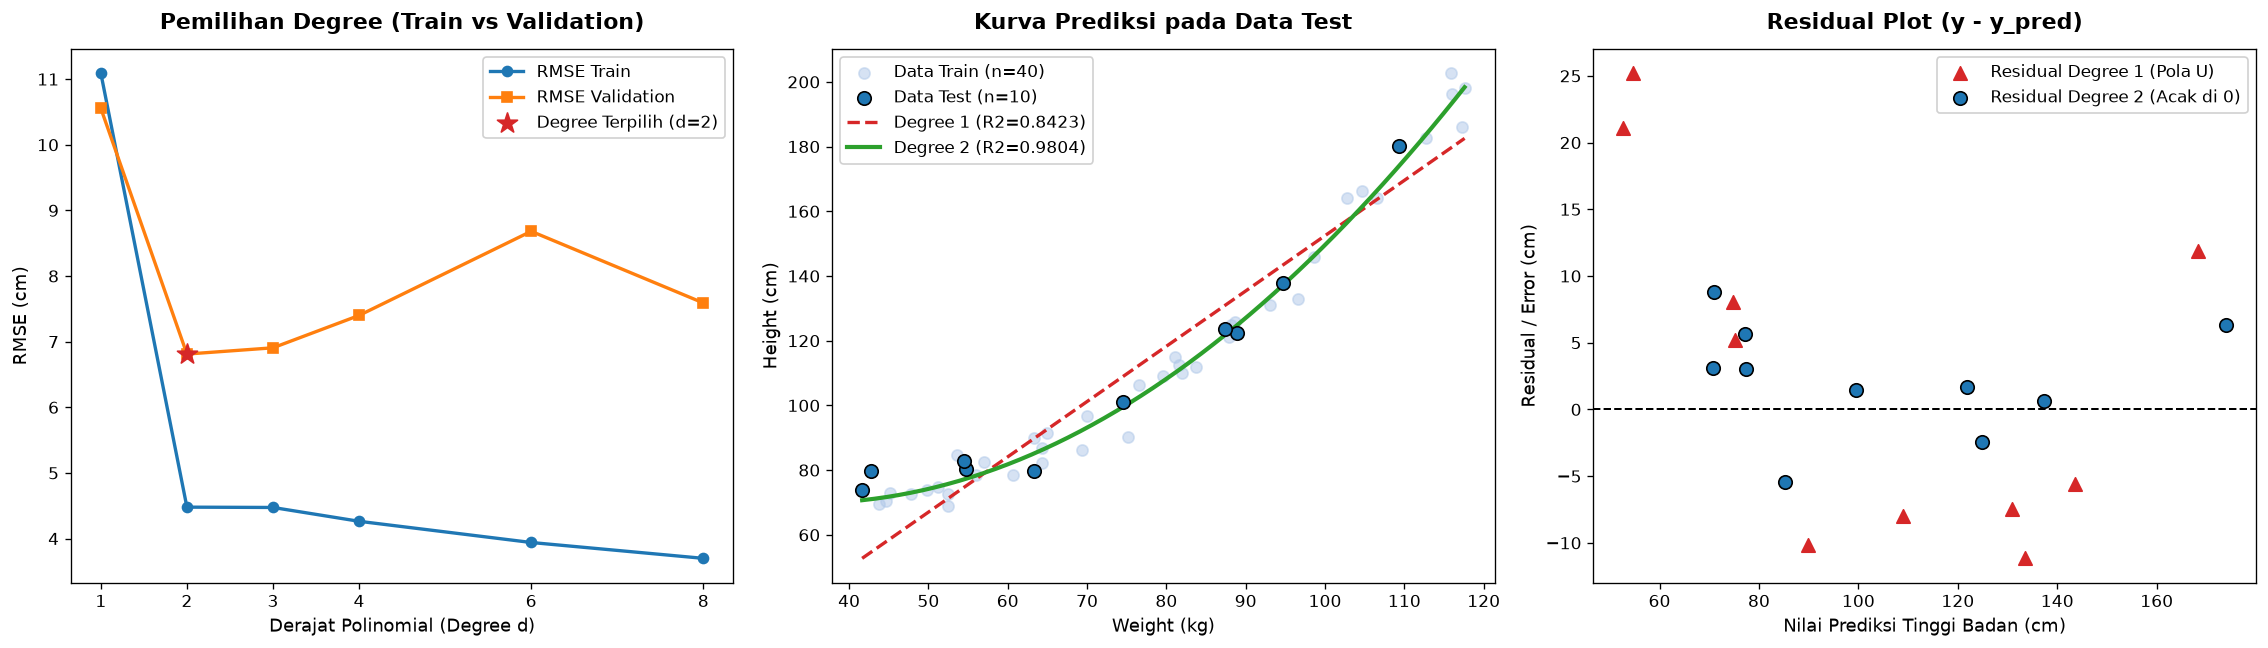

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=120)

degs_plot = [item['Degree (d)'] for item in degree_experiment]
rmse_tr_plot = [float(item['RMSE Train (60%)'].replace(' cm', '')) for item in degree_experiment]
rmse_val_plot = [float(item['RMSE Validation (20%)'].replace(' cm', '')) for item in degree_experiment]

axes[0].plot(degs_plot, rmse_tr_plot, marker='o', color='#1f77b4', linewidth=2, label='RMSE Train')
axes[0].plot(degs_plot, rmse_val_plot, marker='s', color='#ff7f0e', linewidth=2, label='RMSE Validation')
axes[0].scatter([2], [rmse_val_plot[1]], color='#d62728', s=160, zorder=5, marker='*', label='Degree Terpilih (d=2)')
axes[0].set_title('Pemilihan Degree (Train vs Validation)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Derajat Polinomial (Degree d)', fontsize=11)
axes[0].set_ylabel('RMSE (cm)', fontsize=11)
axes[0].set_xticks(degs_plot)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

axes[1].scatter(X_train2, y_train2, color='#aec7e8', alpha=0.5, s=45, label='Data Train (n=40)')
axes[1].scatter(X_test2, y_test2, color='#1f77b4', edgecolor='black', s=65, label='Data Test (n=10)', zorder=4)
x_line = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
_, pred_line_d1, _ = polynomial_regression(X_train2, y_train2, x_line, degree=1)
_, pred_line_d2, _ = polynomial_regression(X_train2, y_train2, x_line, degree=2)
axes[1].plot(x_line, pred_line_d1, color='#d62728', linestyle='--', linewidth=2, label=f'Degree 1 (R2={r2_lin_te:.4f})')
axes[1].plot(x_line, pred_line_d2, color='#2ca02c', linewidth=2.5, label=f'Degree 2 (R2={r2_d2_te:.4f})')
axes[1].set_title('Kurva Prediksi pada Data Test', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Weight (kg)', fontsize=11)
axes[1].set_ylabel('Height (cm)', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

res_d1 = y_test2 - pred_lin2_te
res_d2 = y_test2 - pred_deg2_te
axes[2].axhline(0, color='black', linestyle='--', linewidth=1.2)
axes[2].scatter(pred_lin2_te, res_d1, color='#d62728', marker='^', s=65, label='Residual Degree 1 (Pola U)')
axes[2].scatter(pred_deg2_te, res_d2, color='#1f77b4', marker='o', s=65, edgecolor='black', label='Residual Degree 2 (Acak di 0)')
axes[2].set_title('Residual Plot (y - y_pred)', fontsize=13, fontweight='bold', pad=12)
axes[2].set_xlabel('Nilai Prediksi Tinggi Badan (cm)', fontsize=11)
axes[2].set_ylabel('Residual / Error (cm)', fontsize=11)
axes[2].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### 6.4 Pengujian Bahaya Ekstrapolasi di Luar Rentang Data Latih
Pengujian berikut mendemonstrasikan bahaya matematis ketika model diminta memprediksi di luar rentang:
1. **Weight = 75.0 kg (Interpolasi)**: Berada di dalam rentang normal klien.
2. **Weight = 15.0 kg (Ekstrapolasi Bawah)**: Berat badan balita/anak kecil.
3. **Weight = 160.0 kg (Ekstrapolasi Atas)**: Berat badan atlet/obesitas ekstrem.

In [34]:
pts_test = np.array([[75.0], [15.0], [160.0]])
_, pred_pts_d2, _ = polynomial_regression(X_train2, y_train2, pts_test, degree=2)
_, pred_pts_d6, _ = polynomial_regression(X_train2, y_train2, pts_test, degree=6)

ekstrapolasi_df = pd.DataFrame([
    {
        'Titik Uji Berat Badan': f"Weight = {pts_test[0][0]:.1f} kg",
        'Status Rentang Data': 'Di dalam rentang',
        'Prediksi Degree 2': f"{pred_pts_d2[0]:.2f} cm",
        'Prediksi Degree 6': f"{pred_pts_d6[0]:.2f} cm",
        'Evaluasi Kestabilan Prediksi': 'Kedua model memberikan estimasi yang konsisten dan akurat.'
    },
    {
        'Titik Uji Berat Badan': f"Weight = {pts_test[1][0]:.1f} kg",
        'Status Rentang Data': 'Di luar rentang bawah',
        'Prediksi Degree 2': f"{pred_pts_d2[1]:.2f} cm",
        'Prediksi Degree 6': f"{pred_pts_d6[1]:.2f} cm",
        'Evaluasi Kestabilan Prediksi': 'Kurva parabola berbalik naik; Degree 6 meledak menjadi negatif!'
    },
    {
        'Titik Uji Berat Badan': f"Weight = {pts_test[2][0]:.1f} kg",
        'Status Rentang Data': 'Di luar rentang atas',
        'Prediksi Degree 2': f"{pred_pts_d2[2]:.2f} cm",
        'Prediksi Degree 6': f"{pred_pts_d6[2]:.2f} cm",
        'Evaluasi Kestabilan Prediksi': 'Ekstrapolasi di luar 117.6 kg membuat pangkat tinggi melenceng ribuan sentimeter.'
    }
])
ekstrapolasi_df

,Titik Uji Berat Badan,Status Rentang Data,Prediksi Degree 2,Prediksi Degree 6,Evaluasi Kestabilan Prediksi
0,Weight = 75.0 kg,Di dalam rentang,100.21 cm,100.40 cm,Kedua model memberikan estimasi yang konsisten...
1,Weight = 15.0 kg,Di luar rentang bawah,77.02 cm,-383.94 cm,Kurva parabola berbalik naik; Degree 6 meledak...
2,Weight = 160.0 kg,Di luar rentang atas,363.45 cm,-2321.83 cm,Ekstrapolasi di luar 117.6 kg membuat pangkat ...


### 6.6 Visualisasi Grafik Bahaya Ekstrapolasi
Menampilkan visualisasi zona aman interpolasi $[41.65, 117.59]\text{ kg}$ vs zona bahaya ekstrapolasi di mana kurva Degree 6 mengalami divergensi liar.

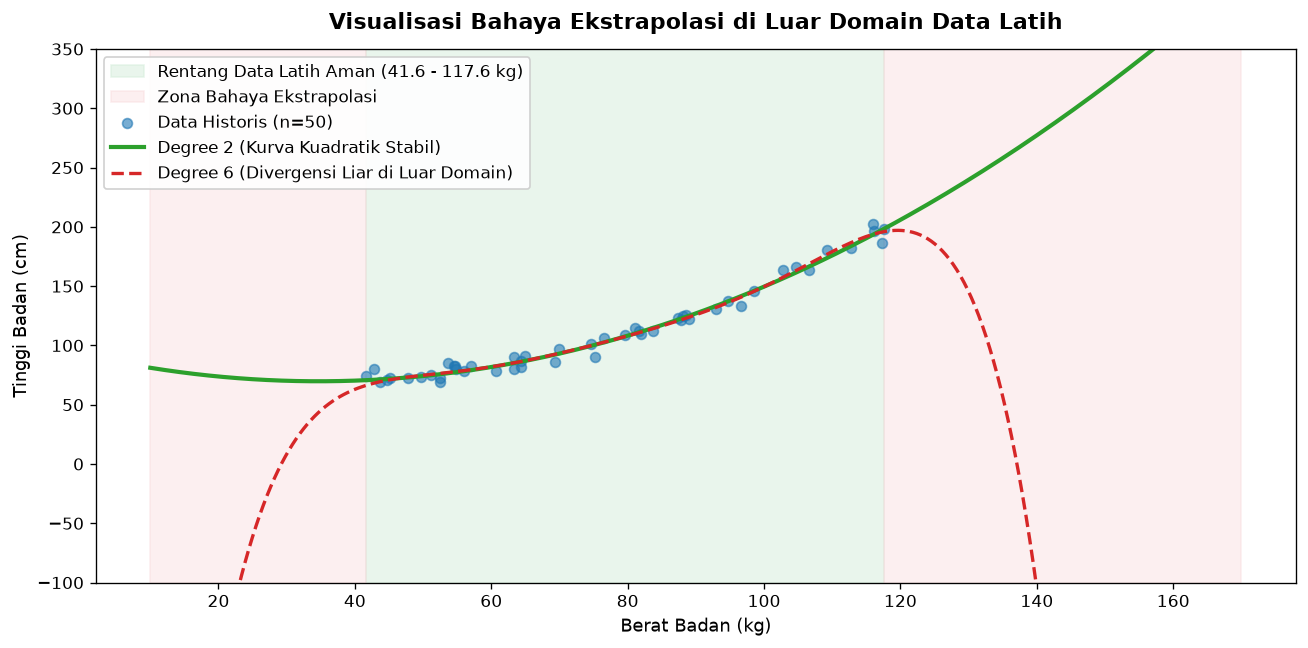

In [35]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)

x_wide = np.linspace(10, 170, 300).reshape(-1, 1)
_, pred_wide_d2, _ = polynomial_regression(X_train2, y_train2, x_wide, degree=2)
_, pred_wide_d6, _ = polynomial_regression(X_train2, y_train2, x_wide, degree=6)

ax.axvspan(X.min(), X.max(), color='#d4edda', alpha=0.5, label=f'Rentang Data Latih Aman ({X.min():.1f} - {X.max():.1f} kg)')
ax.axvspan(10, X.min(), color='#f8d7da', alpha=0.4, label='Zona Bahaya Ekstrapolasi')
ax.axvspan(X.max(), 170, color='#f8d7da', alpha=0.4)

ax.scatter(X, y, color='#1f77b4', s=35, alpha=0.6, label='Data Historis (n=50)')
ax.plot(x_wide, pred_wide_d2, color='#2ca02c', linewidth=2.5, label='Degree 2 (Kurva Kuadratik Stabil)')
ax.plot(x_wide, pred_wide_d6, color='#d62728', linestyle='--', linewidth=2, label='Degree 6 (Divergensi Liar di Luar Domain)')

ax.set_ylim(-100, 350)
ax.set_title('Visualisasi Bahaya Ekstrapolasi di Luar Domain Data Latih', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Berat Badan (kg)', fontsize=11)
ax.set_ylabel('Tinggi Badan (cm)', fontsize=11)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

---

## 7. CONCLUSION

### 7.1 Kesimpulan Analisis
Model Polynomial Regression (Degree 2) terbukti unggul signifikan dibandingkan regresi linier biasa dalam menangkap kelengkungan alami pertumbuhan fisik pada studi kasus prediksi tinggi badan, yang ditunjukkan oleh lonjakan akurasi $R^2$ dari 84.23% menjadi 98.04% (skema 80:20) serta 98.58% (skema 60:20:20), beriringan dengan penurunan drastis RMSE dari 13.01 cm ke rentang 2.56 hingga 4.58 cm. Keberhasilan estimasi ini ditopang oleh penerapan Standardization berbasis data latih yang memangkas condition number matriks $X^T X$ dari $6.67 \times 10^9$ menjadi 9.21 guna mencegah data leakage, serta penerapan aturan toleransi 3% data validasi yang ampuh menangkal risiko overfitting pada derajat tinggi ($d \ge 6$). Seluruh keunggulan representasi non-linier tersebut kian optimal saat dipadukan ke dalam arsitektur multi-target $\hat{Y} = X B$ melalui solusi OLS tunggal $B = (X^T X)^{-1} X^T Y$, yang menghadirkan efisiensi komputasi tinggi untuk memprediksi beragam parameter kesehatan klien secara simultan tanpa pemodelan berulang.



### 7.2 Rekomendasi Operasional bagi Pusat Kesehatan Olahraga dan Nutrisi
Pusat kesehatan dapat mengotomatisasi evaluasi antropometri dengan mengintegrasikan model kuadratik $\hat{y} = 103.1458 - 1.5793(\text{Weight}) + 0.0204(\text{Weight})^2$ ke dalam sistem informasi manajemen klinik untuk menghasilkan estimasi tinggi badan acuan secara instan, presisi, dan objektif. Namun, implementasi perangkat lunak ini wajib dilengkapi validasi batas masukan (anti-extrapolation guardrail) yang membatasi prediksi hanya pada klien berbobot 42 kg hingga 118 kg, sementara data di luar rentang tersebut memerlukan pengumpulan sampel historis baru sebelum domain prediksi diperluas. Sebagai pengembangan lanjutan, fitur polinomial ini dapat dipadukan ke dalam arsitektur Multivariate Regression terpadu agar sistem mampu memproyeksikan beberapa indikator kesehatan sekaligus—seperti tinggi badan, massa otot bebas lemak, dan kebutuhan kalori harian BMR—dalam satu alur komputasi matriks yang efisien.